# Predicting experimental treatment effects
## Cui archive


## How Cui et al. made the predictions

- Prompts asked the model to take the role of an experimental participant. They included the study setting, the scenario and experimental manipulation, outcome questions, and instructions for returning structured responses.
- The authors checked whether models attended to the manipulation and produced usable answers. They report adapting prompts for 35.3% of studies, so these were not all literal copies of the original materials.
- They generated model responses for each condition, matching the original condition's human sample size, and compared the resulting model effects with the published human effects. This did not pair a model response with a particular human respondent.
- The preprint describes GPT-4 and Claude 3.5 Sonnet at temperature 1.0, and DeepSeek V3 at 1.3. Prompts were initially developed with GPT-4 and then used for the other models. Our workshop tables contain aggregate effects and condition means, not matched human–model responses.

Source: Cui, Li and Zhou, **arXiv preprint v3**, “LLM Prompt Design and Validation” and “LLM Replication Process and Data Analysis”. [Preprint](https://arxiv.org/abs/2409.00128v3). The separately released [OSF data](https://osf.io/j6wmn/) are documented in the data guide.


### The example in this notebook

Does an LLM predict how an opening offer changes people’s responses in a negotiation?

We use Study 1 from Ames and Mason (2015), *Tandem Anchoring: Informational and Politeness Effects of Range Offers in Social Exchange*. The description and outcome labels follow the authors’ published paper, pages 257–258 and Table 1. [Read the paper](https://www.columbia.edu/~da358/publications/Tandem_anchoring.pdf).

The LLM results come from Cui, Li and Zhou’s [OSF replication archive](https://osf.io/j6wmn/), study `JPSP_9_1`. Our reading for Cui is [preprint v3, 20 June 2025](https://arxiv.org/abs/2409.00128v3). The packaged OSF tables are documented separately in the [data guide](../data/workshop/cui/README.md).

**What you will do**

- Understand one experiment and make a prediction of your own.
- Compare human and model responses, then calculate treatment effects.
- Change the outcome or model and see whether your conclusion changes.
- Prepare one plot, one finding and one limitation.

Run cells in order with Shift+Enter. A code cell prints a table or draws a figure; the text around it explains what to look for. No model account, API key or coding agent is required.

Open this notebook inside the downloaded repository. The data are included; follow the setup instructions in the repository README.

## Before you run the analysis

Complete the setup in the repository README first. Run the following cell only if you need to install the analysis packages in this notebook’s Python environment. The first installation needs an internet connection. Then run the analysis cells in order.

In [ ]:
%pip install -q numpy pandas matplotlib openpyxl

## 1. Imagine arranging a fundraising dinner

You are organizing a dinner for a nonprofit organization. The menu is already agreed. You are negotiating only the price per person with a caterer.

Participants were randomly assigned to one of four opening offers. All participants took the buyer’s role. The $100 **point offer** is our comparison condition.

| Authors’ condition | Caterer’s opening offer | How it differs from $100 |
|---|---|---|
| Point offer | $100 per person | A single price |
| Bolstering range | $100–$120 | Extends upward, in the seller’s favor |
| Bracketing range | $90–$110 | Extends on both sides |
| Backdown range | $80–$100 | Extends downward, in the buyer’s favor |

Before running the analysis, discuss which offer you expect to produce the highest counteroffer. Would a buyer focus only on the lower end of the range, or would both endpoints matter?

This is a hypothetical negotiation. Participants reported their judgments; they did not negotiate an actual payment with a caterer.

## 2. Three outcomes from the same experiment

| Authors’ outcome | Plain-language meaning |
|---|---|
| Assumed counterpart reservation price | The lowest price participants think the caterer would accept |
| Counteroffer | The single price participants would offer in response |
| Anticipated settlement value | The final price participants think they and the caterer would agree on |

All three are in **dollars per person**. None is an actual settlement. The reservation-price judgment concerns the authors’ proposed informational mechanism, but comparing these outcomes does not establish a causal mediation chain.

We begin with anticipated settlement and the bolstering range. The next cell contains the three choices you can change later.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MODEL = "GPT"  # Or "Claude", "DeepSeek"
OUTCOME = "Anticipated settlement value"
RANGE = "Bolstering range"  # Or "Bracketing range", "Backdown range"
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = str(ROOT / "data/workshop/cui") + "/"
catering = pd.read_csv(DATA + "catering_comparisons.csv")
print(catering.head())

  model  study_id  effect_id  ... human_range model_point  model_range
0   GPT  JPSP_9_1        514  ...        89.1   92.610390   100.576923
1   GPT  JPSP_9_1        515  ...        83.3   83.246753    94.320513
2   GPT  JPSP_9_1        516  ...        77.4   85.584416    93.141026
3   GPT  JPSP_9_1        517  ...        80.7   92.610390    91.551282
4   GPT  JPSP_9_1        518  ...        79.3   83.246753    85.333333

[5 rows x 9 columns]


## 3. Find the catering experiment

An archive row is one comparison for one outcome, not one participant. Study 1 contributes nine rows per model: three ranges compared with the point offer, for each of three outcomes. These comparisons share people and comparison groups.

`catering_comparisons.csv` is a workshop file prepared from the original tables. It gives columns readable names and retains the condition means unchanged. `human_point` and `model_point` refer to the $100 offer; `human_range` and `model_range` refer to the named range. Human means match the rounded values in Table 1.

`pd.read_csv` takes a filename, not a study title. Source mapping and hashes are in `catering_provenance.json`.

In [2]:
study = catering[catering.model == MODEL].copy()
print(study[["range", "outcome", "human_point", "human_range",
             "model_point", "model_range"]].round(2).to_string(index=False))

           range                               outcome  human_point  human_range  model_point  model_range
Bolstering range          Anticipated settlement value         83.7         89.1        92.61       100.58
Bolstering range Assumed counterpart reservation price         77.0         83.3        83.25        94.32
Bolstering range                         Counter offer         73.3         77.4        85.58        93.14
Bracketing range          Anticipated settlement value         83.7         80.7        92.61        91.55
Bracketing range Assumed counterpart reservation price         77.0         79.3        83.25        85.33
Bracketing range                         Counter offer         73.3         74.0        85.58        86.45
  Backdown range          Anticipated settlement value         83.7         72.9        92.61        81.34
  Backdown range Assumed counterpart reservation price         77.0         68.1        83.25        74.95
  Backdown range                     

## 4. Start with the condition means

First ask whether the model places responses at the right level. Then ask whether it captures the change between conditions. A model can get the direction of a change right while placing both means too high.

                    Humans     GPT
Point offer ($100)    83.7   92.61
Bolstering range      89.1  100.58


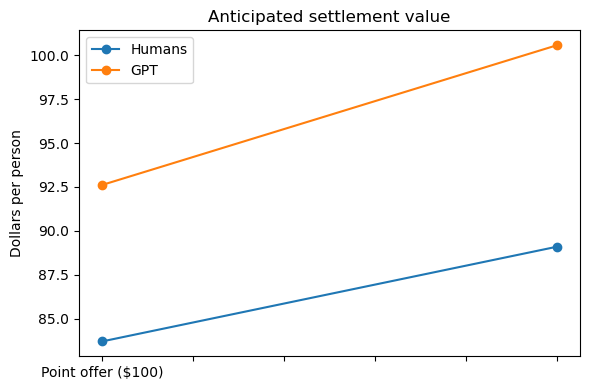

In [3]:
row = study[(study.outcome == OUTCOME) & (study["range"] == RANGE)].iloc[0]
human_means = np.array([row.human_point, row.human_range])
model_means = np.array([row.model_point, row.model_range])
means = pd.DataFrame({"Humans": human_means, MODEL: model_means},
                     index=["Point offer ($100)", RANGE])
means.plot(marker="o", ylabel="Dollars per person", title=OUTCOME, figsize=(6, 4))
plt.tight_layout()
plt.show()
print(means.round(2))

**Reading the initial GPT-4 plot**

- People anticipate $83.70 after the point offer and $89.10 after the bolstering range.
- GPT-4 anticipates about $92.61 and $100.58. Both predicted levels are too high.
- Both lines rise, but the model’s increase is larger. Matching the direction does not mean matching the size of the treatment effect.

These descriptions apply to the initial model, outcome and range. Revisit them when you change those choices.

## 5. Calculate the treatment effect

For every comparison, use the same rule:

**Effect = mean response to the range offer − mean response to the $100 point offer.**

A positive effect means the range increases the response. A negative effect means it decreases the response. This is the effect on the participant’s answer, not the difference between the opening prices themselves.

For the initial human comparison, the calculation is $89.10 − $83.70 = **$5.40 per person**. Now compare that with the model’s effect.

In [4]:
human_effect = human_means[1] - human_means[0]
model_effect = model_means[1] - model_means[0]
error = model_effect - human_effect
print(f"Human effect: ${human_effect:.2f}")
print(f"Model effect: ${model_effect:.2f}")
print(f"Model minus human effect: ${error:.2f}")
print(f"Absolute error: ${abs(error):.2f}")
print("Same direction:", np.sign(human_effect) == np.sign(model_effect))

Human effect: $5.40
Model effect: $7.97
Model minus human effect: $2.57
Absolute error: $2.57
Same direction: True


These are descriptive point estimates. We do not invent individual human records or confidence intervals from the aggregate table. The original article reports tests for its comparisons; these do not turn the model–human difference above into a tested difference.

For example, the bolstering range increased anticipated settlements in the original study, but its counteroffer difference was not statistically significant (p = .12). An effect’s sign alone does not establish that it differs from zero.

Unlike the Ashokkumar and Peng exercises, this notebook cannot simulate revealing fewer human responses or estimate respondent-level PPI efficiency: the supplied Cui tables have no matched individual human responses.

## 6. Does success depend on the outcome or range?

The next plot shows all nine comparisons. Each pair of points compares the human treatment effect with the model treatment effect, in the same units and direction. The zero line marks no change from the $100 point offer.

Mean absolute error across these nine comparisons: $ 1.87
Mean model-minus-human effect: $ 1.13
Comparisons with matching signs: 9 of 9


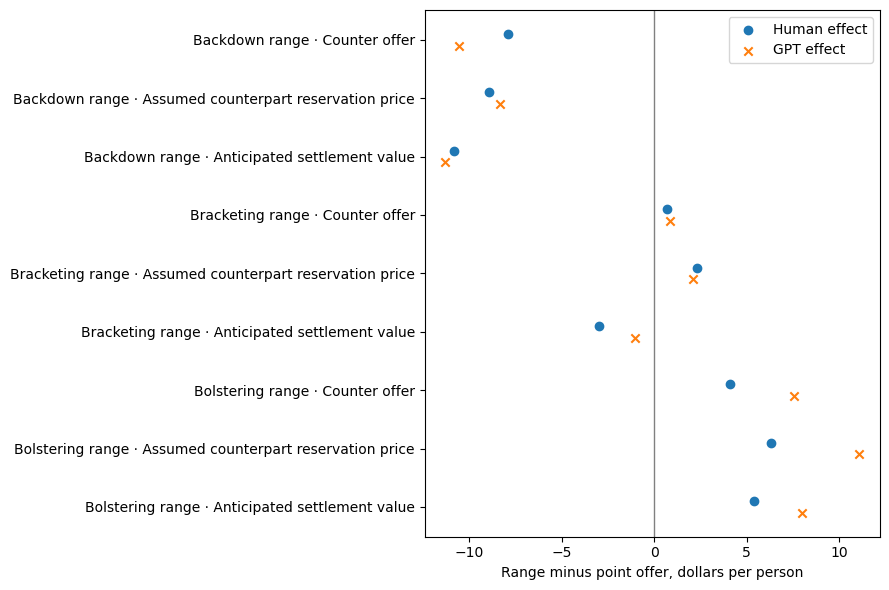

In [5]:
study["human_effect_dollars"] = study["human_range"] - study["human_point"]
study["model_effect_dollars"] = study["model_range"] - study["model_point"]
study["error_dollars"] = study["model_effect_dollars"] - study["human_effect_dollars"]
Y = study["human_effect_dollars"].to_numpy()
Yhat = study["model_effect_dollars"].to_numpy()
labels = study["range"] + " · " + study["outcome"]
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(study))
ax.scatter(Y, y + .1, label="Human effect", marker="o")
ax.scatter(Yhat, y - .1, label=MODEL + " effect", marker="x")
ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(y, labels)
ax.set_xlabel("Range minus point offer, dollars per person")
ax.legend()
fig.tight_layout()
plt.show()
print("Mean absolute error across these nine comparisons: $", round(np.abs(Yhat - Y).mean(), 2))
print("Mean model-minus-human effect: $", round((Yhat - Y).mean(), 2))
print("Comparisons with matching signs:", int((np.sign(Yhat) == np.sign(Y)).sum()), "of", len(Y))

A small average signed error can hide errors in opposite directions. Mean absolute error avoids that cancellation. Matching signs says nothing about whether the magnitudes are close. These nine comparisons are dependent, so treat these summaries as descriptions of this example, not nine independent tests of model performance.

**Try one change at a time**

1. Return to the choices cell and change `OUTCOME` to `Counter offer` or `Assumed counterpart reservation price`. Run that cell and all cells below it.
2. Change `RANGE` to `Bracketing range` or `Backdown range` and repeat.
3. Change `MODEL` to `Claude` or `DeepSeek`. Does a conclusion based on GPT-4 still hold?

Write down what you changed and whether your conclusion concerns levels, direction or effect size. You do not need to write a new function.

## 7. Optional exploration across the archive

Other studies measure different things, so dollar differences cannot be compared across the whole archive. Cui provides effects converted to a common metric, r. These are **standardized effect sizes**, not correlations between matched people and their predictions.

For this optional plot, compare their magnitudes using absolute values. This asks whether effects reported as larger in humans are also larger in the model. It does not assess treatment-effect direction. The archive’s recoded model sign uses agreement with the human result; it must not be treated as an independently oriented prospective prediction.

The converted measures inherit the archive’s coding and assumptions. We deliberately used the original condition means for the catering exercise. Main-effect tables can include different test types and contrasts; inspect the original study before interpreting another row causally. We leave interactions out of this plot.

Complete effect rows: 661 of 690


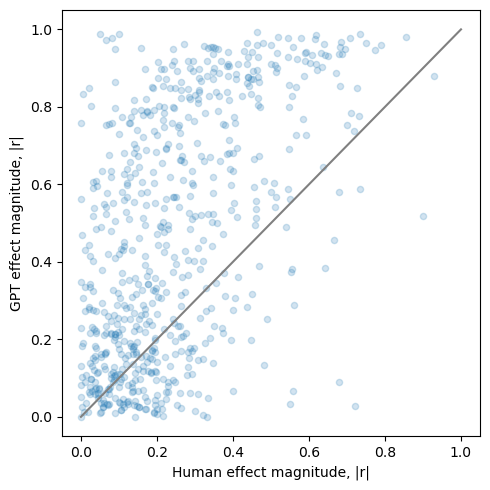

In [6]:
effects = pd.read_csv(DATA + f"enhanced_dataset_{MODEL}_main.csv")
r_columns = {"GPT": "Gpt_r_recode", "Claude": "Claude_r_recode", "DeepSeek": "DeepSeek_r_recode"}
magnitudes = effects[["Human_r", r_columns[MODEL]]].apply(pd.to_numeric, errors="coerce").dropna().abs()
magnitudes.columns = ["Human", "Model"]
print("Complete effect rows:", len(magnitudes), "of", len(effects))
magnitudes.plot.scatter(x="Human", y="Model", alpha=.2, figsize=(5, 5))
plt.plot([0, 1], [0, 1], color="grey")
plt.xlabel("Human effect magnitude, |r|")
plt.ylabel(MODEL + " effect magnitude, |r|")
plt.tight_layout()
plt.show()

The diagonal marks equal magnitudes. Points above it have larger model effects. Several points may come from one experiment, and experiments contribute different numbers of points. This is a descriptive plot, not an inferential meta-analysis or a PPI efficiency calculation. Missing effects are not automatically failed replications.

If you choose another study, first read its `IV` and `DV`, identify its treatment and comparison conditions, and check the original paper. Ask whether apparent prediction errors depend on the outcome, treatment, model or metric.

## Share your result

- Show one comparison or plot.
- State one finding in plain language, with the model and outcome named.
- Give one limitation and one question to investigate next.

A few bullet points are enough. For example, distinguish “the model gets the direction right” from “the model gets the dollar change right.”

## Sources and preparation

- Ames and Mason (2015), [published article](https://doi.org/10.1037/pspi0000016), Study 1, Table 1 and the appendix’s catering scenario. [Author-hosted full text](https://www.columbia.edu/~da358/publications/Tandem_anchoring.pdf).
- Cui, Li and Zhou, [preprint v3](https://arxiv.org/abs/2409.00128v3), the manuscript used for this workshop.
- [OSF replication archive](https://osf.io/j6wmn/), final main-effect tables, `study_id == "JPSP_9_1"`, effect IDs 514–522. The tables are included unchanged; source hashes and verification details are in [provenance.json](../data/workshop/cui/provenance.json).

The study was chosen for its understandable treatment, common dollar scale and three outcomes. It was not selected to maximize a prediction score. No source analysis scripts or model calls are needed. The OSF dataset has no declared licence; the preprint’s licence is not assigned to these data.